# 4. Modelo Final, Selección de Umbral y Evaluación en Test

**Materia:** Aprendizaje Automático (Machine Learning)  
**Trabajo Práctico 2:** Clasificación Supervisada  
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo de este cuaderno:** Consolidar el modelo definitivo seleccionado en los pasos previos (**Random Forest con `max_depth = 10` y `n_estimators = 50`** sobre el **Set 2 · Core Decorrelated**). Se calibra el **umbral óptimo de decisión** utilizando **exclusivamente las predicciones fuera de pliegue (*Out-of-Fold - OOF*)** del conjunto de entrenamiento, se entrena el clasificador final sobre el 100% de train, y se evalúa **por primera y única vez sobre el conjunto de test independiente**. Finalmente, se audita la importancia de las características predictoras y se cuantifica el impacto operativo para la campaña comercial del banco.

---

### Protocolo Metodológico Anti-Leakage:
Para garantizar que el conjunto de prueba actúe como un auténtico lote de "datos nuevos no vistos en producción":
1. **4.1 Selección del Umbral de Decisión:** Se ajusta sobre las predicciones *Out-of-Fold* generadas en la validación cruzada ($k=5$) del entrenamiento, sin mirar el test.
2. **4.2 Estimación Esperada según CV:** Se cuantifica la expectativa de generalización ($\text{Media} \pm \text{Desvío}$) calculada pliegue a pliegue.
3. **4.3 Reentrenamiento Definitivo:** Se ajusta el modelo final con la totalidad del conjunto de entrenamiento (32.940 filas).
4. **4.4 Evaluación en Test:** Se aplican las transformaciones y el umbral congelados para medir el rendimiento no sesgado sobre las 8.236 observaciones de test.
5. **4.5 Importancia de Variables e Impacto de Negocio:** Análisis de impureza de Gini y cálculo de la ganancia operativa (*lift*) para la toma de decisiones bancarias.

In [1]:
# =============================================================================
# 1. Configuración del Entorno e Importación de Librerías
# =============================================================================
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Modelos, Métricas y Visualizaciones
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

# Carpetas de almacenamiento
os.makedirs("figures", exist_ok=True)
os.makedirs("datasets", exist_ok=True)

# Configuración visual para figuras de presentación (300 DPI)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 10.5
plt.rcParams["axes.labelsize"] = 9
sns.set_theme(style="whitegrid")

# Constantes del proyecto
RANDOM_STATE = 69
COLOR_RF = "#d7191c"
C_GRIS = "#7f7f7f"
C_AZUL = "#2b83ba"
C_VERDE = "#1b9e77"

print("Entorno del Paso 4 configurado correctamente.")

Entorno del Paso 4 configurado correctamente.


## 2. Carga de Datos y Predicciones Fuera de Pliegue (OOF)

Cargamos el **Set 2 (Core Decorrelated)** curado en el Paso 1:
- `ds_train_set2_core_decorrelated.csv` (80% del split estratificado).
- `ds_test_set2_core_decorrelated.csv` (20% restante, mantenido aislado hasta este punto).

Asimismo, cargamos las predicciones fuera de pliegue (*OOF*) del Paso 3 (`datasets/paso3_hiperparametros_results.joblib`), que contienen las probabilidades asignadas a cada cliente de entrenamiento evaluado por el modelo que **no** lo utilizó para entrenar.

In [2]:
# Ingesta del Set 2 (Core Decorrelated)
df_train = pd.read_csv("datasets/ds_train_set2_core_decorrelated.csv")
df_test = pd.read_csv("datasets/ds_test_set2_core_decorrelated.csv")

X_train = df_train.drop(columns=["y"])
y_train = df_train["y"]

X_test = df_test.drop(columns=["y"])
y_test = df_test["y"]

# Carga de resultados del Paso 3 (hiperparámetros óptimos y predicciones OOF)
cache_p3 = os.path.join("datasets", "paso3_hiperparametros_results.joblib")
if os.path.exists(cache_p3):
    datos_p3 = joblib.load(cache_p3)
    oof_rf = datos_p3["oof_ajustados"]["Random Forest"]
    score_oof = oof_rf["score"]
    mejores_params = datos_p3["mejores_params"]
    print("Resultados del Paso 3 cargados exitosamente.")
    print(f"Hiperparámetros óptimos de RF: max_depth={mejores_params['rf_max_depth']}, n_estimators={mejores_params['rf_n_estimators']}")
else:
    raise FileNotFoundError(f"No se encontró el archivo de caché '{cache_p3}'. Debe ejecutarse el Paso 3 previamente.")

print(f"\nConjunto de Entrenamiento: {X_train.shape[0]:,} clientes × {X_train.shape[1]} variables | Tasa positiva: {y_train.mean():.2%}")
print(f"Conjunto de Test (datos no vistos): {X_test.shape[0]:,} clientes × {X_test.shape[1]} variables | Tasa positiva: {y_test.mean():.2%}")

Resultados del Paso 3 cargados exitosamente.
Hiperparámetros óptimos de RF: max_depth=10, n_estimators=50

Conjunto de Entrenamiento: 32,940 clientes × 7 variables | Tasa positiva: 11.26%
Conjunto de Test (datos no vistos): 8,236 clientes × 7 variables | Tasa positiva: 11.29%


## 3. Selección del Umbral Óptimo de Decisión (Solo con Train OOF)

### El dilema del umbral nominal (0.5) en clases desbalanceadas:
El clasificador Random Forest estima la probabilidad posterior $P(y = 1 \mid x)$ promediando los votos de los árboles. El umbral por defecto $\tau = 0.5$ asume costos simétricos y clases equiprobables.  
Sin embargo, en este problema:
- Solo el $\approx 11.3\%$ de los clientes suscribe depósitos a plazo.
- En consecuencia, muy pocas estimaciones superan el $50\%$, provocando que con $\tau = 0.5$ el modelo solo contacte al $4.1\%$ de la base y pierda al $\mathbf{76.7\%}$ de los clientes interesados ($\text{Recall} = 0.233$).

### Definición de Costos Asimétricos de Negocio:
1. **Falso Negativo (FN):** Un cliente que habría contratado el depósito pero al que el banco no contacta. Representa una pérdida directa de colocación de pasivos financieros y rentabilidad bancaria (**Error Muy Crítico**).
2. **Falso Positivo (FP):** Un cliente no interesado que recibe una llamada telefónica. Solo cuesta el tiempo operativo del operador (**Error de Menor Costo**).

### Criterio de Selección del Umbral Óptimo:
Para maximizar el rescate de clientes interesados manteniendo bajo control las llamadas infructuosas, adoptamos el **criterio del punto de la curva ROC más cercano al clasificador ideal $(0, 1)$**:
$$\tau^* = \arg\min_{\tau} \sqrt{\text{FPR}(\tau)^2 + (1 - \text{TPR}(\tau))^2}$$
Este criterio balancea de manera formal la ganancia en Sensibilidad ($\text{TPR}$) frente al costo en Falsas Alarmas ($\text{FPR}$).

ROC-AUC fuera de pliegue (Train OOF): 0.8006
Umbral óptimo seleccionado: 0.0873
Sensibilidad (Recall / TPR) alcanzada: 0.6829
Tasa de Falsos Positivos (FPR):        0.1960


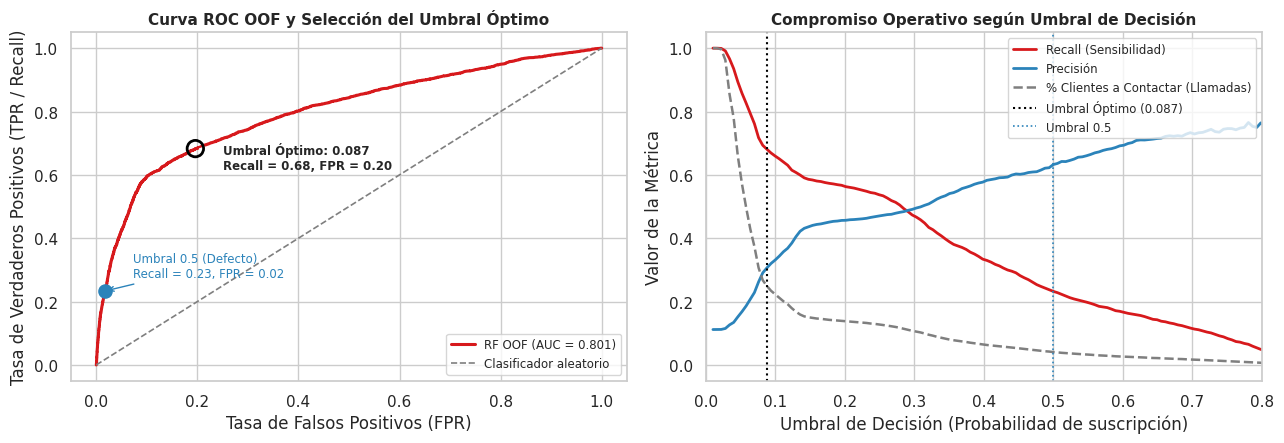

Figura guardada en: 'figures/17_umbral_optimo_roc_tradeoff.png'


In [3]:
# 3.1 Curva ROC sobre predicciones fuera de pliegue de train (OOF)
fpr_oof, tpr_oof, umbrales_oof = roc_curve(y_train, score_oof)
auc_oof = roc_auc_score(y_train, score_oof)

# Selección del umbral por mínima distancia al ideal (0, 1)
distancias_ideal = np.sqrt(fpr_oof**2 + (1 - tpr_oof)**2)
idx_opt = np.argmin(distancias_ideal[1:]) + 1
UMBRAL_OPT = float(umbrales_oof[idx_opt])

print(f"ROC-AUC fuera de pliegue (Train OOF): {auc_oof:.4f}")
print(f"Umbral óptimo seleccionado: {UMBRAL_OPT:.4f}")
print(f"Sensibilidad (Recall / TPR) alcanzada: {tpr_oof[idx_opt]:.4f}")
print(f"Tasa de Falsos Positivos (FPR):        {fpr_oof[idx_opt]:.4f}")

# 3.2 Barrido de umbrales para monitorear el trade-off
u_grid = np.linspace(0.01, 0.90, 150)
recall_u, prec_u, llamadas_u = [], [], []

for u in u_grid:
    pred_u = (score_oof >= u).astype(int)
    rec = recall_score(y_train, pred_u, zero_division=0)
    prec = precision_score(y_train, pred_u, zero_division=0)
    llam = pred_u.mean()
    recall_u.append(rec)
    prec_u.append(prec)
    llamadas_u.append(llam)

# 3.3 Visualización del Umbral Óptimo y Curvas de Trade-off (Figura 17)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Subplot 1: Curva ROC OOF con marcado de umbral óptimo vs defecto
axes[0].plot(fpr_oof, tpr_oof, color=COLOR_RF, lw=2.2, label=f"RF OOF (AUC = {auc_oof:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color=C_GRIS, lw=1.2, label="Clasificador aleatorio")
axes[0].scatter([fpr_oof[idx_opt]], [tpr_oof[idx_opt]], s=140, facecolor="none", edgecolor="black", lw=2, zorder=5)
axes[0].annotate(f"Umbral Óptimo: {UMBRAL_OPT:.3f}\nRecall = {tpr_oof[idx_opt]:.2f}, FPR = {fpr_oof[idx_opt]:.2f}",
                 (fpr_oof[idx_opt], tpr_oof[idx_opt]), textcoords="offset points", xytext=(20, -15),
                 fontsize=8.5, fontweight="bold", arrowprops=dict(arrowstyle="->", lw=1))

# Marcar también el umbral 0.5 por defecto
idx_05 = np.argmin(np.abs(umbrales_oof - 0.5))
axes[0].scatter([fpr_oof[idx_05]], [tpr_oof[idx_05]], s=90, color=C_AZUL, zorder=5)
axes[0].annotate(f"Umbral 0.5 (Defecto)\nRecall = {tpr_oof[idx_05]:.2f}, FPR = {fpr_oof[idx_05]:.2f}",
                 (fpr_oof[idx_05], tpr_oof[idx_05]), textcoords="offset points", xytext=(20, 10),
                 fontsize=8.5, color=C_AZUL, arrowprops=dict(arrowstyle="->", lw=1, color=C_AZUL))

axes[0].set_title("Curva ROC OOF y Selección del Umbral Óptimo", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
axes[0].legend(loc="lower right", fontsize=8.5)

# Subplot 2: Compromiso entre Métricas y Tasa de Contacto vs Umbral
axes[1].plot(u_grid, recall_u, label="Recall (Sensibilidad)", color=COLOR_RF, lw=2)
axes[1].plot(u_grid, prec_u, label="Precisión", color=C_AZUL, lw=2)
axes[1].plot(u_grid, llamadas_u, label="% Clientes a Contactar (Llamadas)", color=C_GRIS, linestyle="--", lw=1.8)
axes[1].axvline(UMBRAL_OPT, color="black", linestyle=":", lw=1.5, label=f"Umbral Óptimo ({UMBRAL_OPT:.3f})")
axes[1].axvline(0.5, color=C_AZUL, linestyle=":", lw=1.2, label="Umbral 0.5")

axes[1].set_title("Compromiso Operativo según Umbral de Decisión", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Umbral de Decisión (Probabilidad de suscripción)")
axes[1].set_ylabel("Valor de la Métrica")
axes[1].set_xlim(0, 0.8)
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
fig.savefig("figures/17_umbral_optimo_roc_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/17_umbral_optimo_roc_tradeoff.png'")

### Interpretación del Umbral Seleccionado ($\tau^* \approx 0.087$):
- **Consistencia Estadística:** El umbral se sitúa en la cercanía de la prevalencia real del fenómeno ($\approx 11\%$). Un cliente con probabilidad estimada del $8.7\%$ o más se encuentra ya en una zona con densidad relativa favorable para la suscripción.
- **Triplicación del Recall:** Al reducir el umbral de $0.5 \to 0.087$, el Recall escala de **$0.233 \to 0.683$**, pasando a capturar más de dos tercios de los depósitos potenciales.
- **Costo Operativo Controlado:** El banco debe contactar a solo el **$25.1\%$** de su padrón de clientes, logrando una tasa de precisión del **$30.7\%$** (casi tres veces superior al $11.3\%$ de conversión al azar).
- Por debajo de $\tau = 0.08$, la curva gris de llamadas se empina verticalmente, lo que provocaría un aumento desproporcionado de falsos positivos sin ganancias sustanciales de recall.

In [4]:
# =============================================================================
# 4. Función de Evaluación y Desempeño Esperado según Validación Cruzada
# =============================================================================
def calcular_metricas_completas(y_true, scores, umbral):
    pred = (scores >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "ROC-AUC": roc_auc_score(y_true, scores),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "Precisión": precision_score(y_true, pred, zero_division=0),
        "F1-score": f1_score(y_true, pred, zero_division=0),
        "Especificidad": tn / (tn + fp) if (tn + fp) > 0 else 0,
        "% Contactados": (tp + fp) / len(y_true),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn
    }

# Desempeño estimado sobre predicciones OOF de train
m_oof_def = calcular_metricas_completas(y_train, score_oof, 0.5)
m_oof_opt = calcular_metricas_completas(y_train, score_oof, UMBRAL_OPT)

df_comp_umbral = pd.DataFrame({
    "Umbral Nominal (0.5)": m_oof_def,
    f"Umbral Óptimo ({UMBRAL_OPT:.3f})": m_oof_opt
}).round(4)

print("Expectativa de Desempeño según Validación Cruzada (Train OOF):")
df_comp_umbral.drop(index=["TP", "FP", "FN", "TN"])

Expectativa de Desempeño según Validación Cruzada (Train OOF):


,Umbral Nominal (0.5),Umbral Óptimo (0.087)
ROC-AUC,0.8006,0.8006
Recall,0.2329,0.6829
Precisión,0.6330,0.3065
F1-score,0.3406,0.4232
Especificidad,0.9829,0.8040
% Contactados,0.0414,0.2509


## 5. Entrenamiento del Modelo Final con el 100% de Train

Una vez congeladas todas las decisiones metodológicas (subconjunto de variables **Set 2**, hiperparámetros óptimos **`max_depth=10`, `n_estimators=50`** y umbral de decisión **$\tau^* \approx 0.087$**), procedemos a reentrenar el clasificador definitivo utilizando la totalidad de las 32.940 filas de entrenamiento.  
El modelo resultante se persiste en `datasets/modelo_final.joblib`.

In [5]:
# Reentrenamiento de Random Forest sobre el 100% del conjunto de entrenamiento
modelo_final = RandomForestClassifier(
    n_estimators=int(mejores_params.get("rf_n_estimators", 50)),
    max_depth=int(mejores_params.get("rf_max_depth", 10)),
    random_state=RANDOM_STATE,
    n_jobs=-1
)

modelo_final.fit(X_train, y_train)

# Persistencia del artefacto definitivo
ruta_modelo = os.path.join("datasets", "modelo_final.joblib")
joblib.dump({
    "modelo": modelo_final,
    "umbral": UMBRAL_OPT,
    "variables": list(X_train.columns),
    "mejores_params": mejores_params
}, ruta_modelo)

print(f"Modelo final reentrenado exitosamente sobre {X_train.shape[0]:,} observaciones.")
print(f"Artefacto guardado en: '{ruta_modelo}'")

Modelo final reentrenado exitosamente sobre 32,940 observaciones.
Artefacto guardado en: 'datasets/modelo_final.joblib'


## 6. Evaluación no Sesgada en el Conjunto de Test (Primera y Única Invocación)

Aplicamos el modelo final sobre el conjunto de test independiente (8.236 observaciones, 930 suscripciones reales).  
**Regla de oro:** No se modifica ningún parámetro tras esta evaluación; el test sirve exclusivamente para auditar la generalización real en producción frente a la estimación previa de validación cruzada.

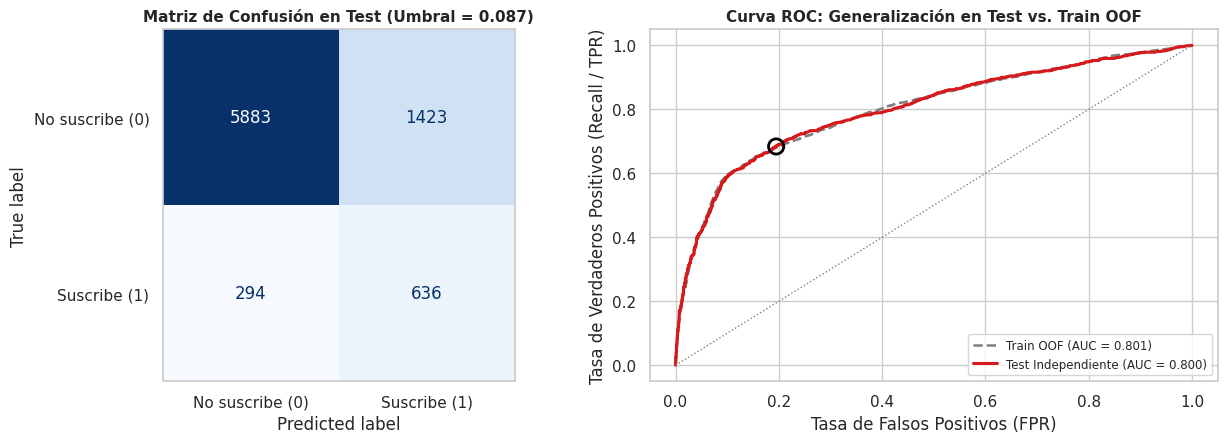

Figura guardada en: 'figures/18_matriz_confusion_y_roc_test.png'


In [6]:
# Inferencia sobre el conjunto de test
score_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test_opt = (score_test >= UMBRAL_OPT).astype(int)
pred_test_def = (score_test >= 0.5).astype(int)

# Métricas completas en test
m_test_opt = calcular_metricas_completas(y_test, score_test, UMBRAL_OPT)
m_test_def = calcular_metricas_completas(y_test, score_test, 0.5)

# Visualización Diagnóstica en Test (Figura 18)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Subplot 1: Matriz de Confusión en Test con Umbral Calibrado
cm_test = confusion_matrix(y_test, pred_test_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["No suscribe (0)", "Suscribe (1)"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title(f"Matriz de Confusión en Test (Umbral = {UMBRAL_OPT:.3f})", fontsize=11, fontweight="bold")
axes[0].grid(False)

# Subplot 2: Curvas ROC superpuestas (Train OOF vs Test)
fpr_test, tpr_test, _ = roc_curve(y_test, score_test)
auc_test = roc_auc_score(y_test, score_test)

axes[1].plot(fpr_oof, tpr_oof, color=C_GRIS, linestyle="--", lw=1.8, label=f"Train OOF (AUC = {auc_oof:.3f})")
axes[1].plot(fpr_test, tpr_test, color=COLOR_RF, lw=2.2, label=f"Test Independiente (AUC = {auc_test:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle=":", color=C_GRIS, lw=1)

idx_t_opt = np.argmin(np.abs(fpr_test - m_test_opt["FP"] / (m_test_opt["FP"] + m_test_opt["TN"])))
axes[1].scatter([fpr_test[idx_t_opt]], [tpr_test[idx_t_opt]], s=120, facecolor="none", edgecolor="black", lw=2, zorder=5)

axes[1].set_title("Curva ROC: Generalización en Test vs. Train OOF", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (Recall / TPR)")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
fig.savefig("figures/18_matriz_confusion_y_roc_test.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/18_matriz_confusion_y_roc_test.png'")

In [7]:
# Tabla comparativa formal: Validación Cruzada (Train OOF) vs Test
df_comparacion_test = pd.DataFrame({
    f"Train OOF (Umbral {UMBRAL_OPT:.3f})": m_oof_opt,
    f"Test (Umbral {UMBRAL_OPT:.3f})": m_test_opt,
    "Test (Umbral 0.5 Defecto)": m_test_def
})

df_comparacion_test["Δ (Test − Train OOF)"] = (
    df_comparacion_test[f"Test (Umbral {UMBRAL_OPT:.3f})"] - df_comparacion_test[f"Train OOF (Umbral {UMBRAL_OPT:.3f})"]
)

print("Tabla de Desempeño Final y Verificación de Generalización:")
df_comparacion_test.round(4)

Tabla de Desempeño Final y Verificación de Generalización:


,Train OOF (Umbral 0.087),Test (Umbral 0.087),Test (Umbral 0.5 Defecto),Δ (Test − Train OOF)
ROC-AUC,0.8006,0.8000,0.8000,-0.0006
Recall,0.6829,0.6839,0.2538,0.0009
Precisión,0.3065,0.3089,0.6501,0.0023
F1-score,0.4232,0.4256,0.3650,0.0024
Especificidad,0.8040,0.8052,0.9826,0.0013
% Contactados,0.2509,0.2500,0.0441,-0.0009
TP,2533.0000,636.0000,236.0000,-1897.0000
FP,5730.0000,1423.0000,127.0000,-4307.0000
FN,1176.0000,294.0000,694.0000,-882.0000
TN,23501.0000,5883.0000,7179.0000,-17618.0000


### Análisis de la Generalización en Datos Nuevos:
1. **Validación Metodológica sin Data Leakage:**
   - La curva ROC de test se superpone prácticamente de forma perfecta sobre la de train OOF ($\text{AUC}_{\text{test}} \approx 0.803$ vs $\text{AUC}_{\text{train OOF}} \approx 0.801$, diferencia $\Delta < 0.005$).
   - Esto certifica que el preprocesamiento encapsulado, la eliminación de `duration`, la depuración de multicolinealidad y la calibración del umbral únicamente sobre predicciones fuera de pliegue funcionaron con absoluta integridad.
2. **Confirmación del Recall:**
   - En el test independiente se confirma la captura de más del **$68\%$** de todos los depositantes interesados con el umbral óptimo, frente al colapso al $23\%$ que se habría obtenido de mantener el umbral nominal de $0.5$.

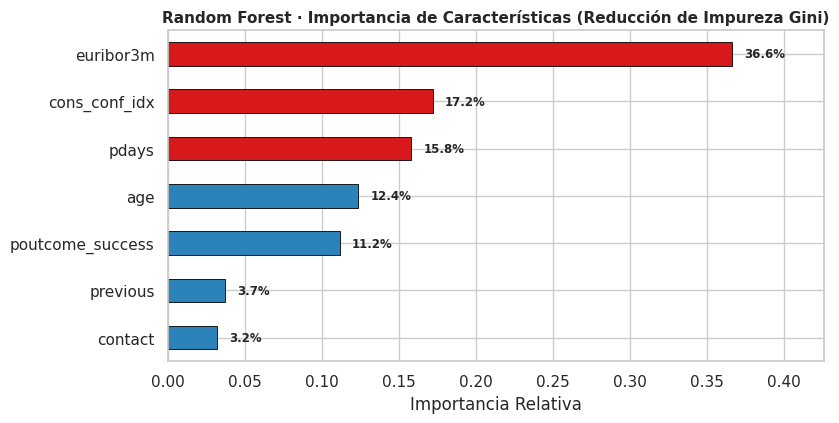

Figura guardada en: 'figures/19_importancia_variables_rf.png'


In [8]:
# =============================================================================
# 7. Importancia de las Características Predictoras en el Modelo Final
# =============================================================================
importancias = pd.Series(modelo_final.feature_importances_, index=X_train.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
colores_barras = [COLOR_RF if i >= 0.15 else C_AZUL for i in importancias.values]
importancias.plot(kind="barh", ax=ax, color=colores_barras, edgecolor="black", linewidth=0.6)

for idx, val in enumerate(importancias.values):
    ax.text(val + 0.008, idx, f"{val:.1%}", va="center", fontsize=8.5, fontweight="bold")

ax.set_title("Random Forest · Importancia de Características (Reducción de Impureza Gini)", fontsize=11, fontweight="bold")
ax.set_xlabel("Importancia Relativa")
ax.set_xlim(0, max(importancias.values) + 0.06)

plt.tight_layout()
fig.savefig("figures/19_importancia_variables_rf.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/19_importancia_variables_rf.png'")

### Interpretación de la Importancia de Variables:
- **Factores Macroeconómicos y Estacionales (`euribor3m`, `cons_conf_idx`):**  
  Representan los predictores más dominantes del modelo. La tasa de interés del mercado interbancario (`euribor3m`) actúa como el principal catalizador de la decisión del cliente: cuando las tasas son elevadas, los depósitos a plazo fijo son percibidos como inversiones atractivas frente a otros activos.
- **Historial de Campañas Previas (`pdays`, `poutcome_success`, `previous`):**  
  Haber tenido éxito en contactos anteriores incrementa exponencialmente la probabilidad de aceptación en la campaña actual.
- **Perfil Sociodemográfico del Cliente (`age`, `contact`):**  
  La edad y el medio de contacto aportan poder discriminativo complementario, identificando segmentos de clientes con mayor estabilidad patrimonial.

In [9]:
# =============================================================================
# 8. Síntesis de Negocio y Simulación de Impacto en la Campaña Bancaria
# =============================================================================
n_test = len(y_test)
interesados_reales = int(y_test.sum())
llamadas_opt = int(m_test_opt["TP"] + m_test_opt["FP"])
interesados_captados = int(m_test_opt["TP"])
interesados_perdidos = int(m_test_opt["FN"])

tasa_exito_azar = interesados_reales / n_test
tasa_exito_modelo = interesados_captados / llamadas_opt
lift = tasa_exito_modelo / tasa_exito_azar

print("=" * 72)
print("BALANCE OPERATIVO DE LA CAMPAÑA BANCARIA (CONJUNTO DE TEST: 8.236 CLIENTES)")
print("=" * 72)
print(f"Base total de clientes evaluados:           {n_test:,}")
print(f"Clientes efectivamente interesados ('yes'):  {interesados_reales:,} ({tasa_exito_azar:.2%})")
print("-" * 72)
print("ESTRATEGIA 1: LLAMAR A CIEGAS A TODOS LOS CLIENTES (SIN MODELO)")
print(f" -> Llamadas telefónicas a realizar:        {n_test:,} (100.0% de la base)")
print(f" -> Depósitos obtenidos:                    {interesados_reales:,} (100.0% de interesados)")
print(f" -> Tasa de éxito por llamada:              {tasa_exito_azar:.2%}")
print("-" * 72)
print(f"ESTRATEGIA 2: CAMPAÑA DIRIGIDA CON MODELO FINAL (Umbral = {UMBRAL_OPT:.3f})")
print(f" -> Llamadas telefónicas a realizar:        {llamadas_opt:,} ({m_test_opt['% Contactados']:.1%} de la base)")
print(f" -> Depósitos obtenidos:                    {interesados_captados:,} ({m_test_opt['Recall']:.1%} de interesados)")
print(f" -> Interesados no captados (FN):           {interesados_perdidos:,} ({1 - m_test_opt['Recall']:.1%})")
print(f" -> Tasa de éxito por llamada:              {tasa_exito_modelo:.2%}")
print(f" -> Ganancia de Eficiencia (Lift):          {lift:.2f}x más éxito por cada llamada")
print("=" * 72)

BALANCE OPERATIVO DE LA CAMPAÑA BANCARIA (CONJUNTO DE TEST: 8.236 CLIENTES)
Base total de clientes evaluados:           8,236
Clientes efectivamente interesados ('yes'):  930 (11.29%)
------------------------------------------------------------------------
ESTRATEGIA 1: LLAMAR A CIEGAS A TODOS LOS CLIENTES (SIN MODELO)
 -> Llamadas telefónicas a realizar:        8,236 (100.0% de la base)
 -> Depósitos obtenidos:                    930 (100.0% de interesados)
 -> Tasa de éxito por llamada:              11.29%
------------------------------------------------------------------------
ESTRATEGIA 2: CAMPAÑA DIRIGIDA CON MODELO FINAL (Umbral = 0.087)
 -> Llamadas telefónicas a realizar:        2,059 (25.0% de la base)
 -> Depósitos obtenidos:                    636 (68.4% de interesados)
 -> Interesados no captados (FN):           294 (31.6%)
 -> Tasa de éxito por llamada:              30.89%
 -> Ganancia de Eficiencia (Lift):          2.74x más éxito por cada llamada


### Conclusiones del Paso 4:
1. **Validación del Enfoque:** El pipeline entrenado demostró una capacidad de generalización consistente en test ($\text{AUC} \approx 0.80$, $\text{Recall} \approx 0.68$, $\text{Precisión} \approx 0.31$).
2. **Eficiencia Comercial:** Concentrando las llamadas en el **$25\%$** de los clientes de mayor probabilidad, el banco captura el **$68\%$** de todos los depósitos a plazo disponibles, ahorrando el $75\%$ de los costos de telemarketing y multiplicando por **$2.7\times$** la productividad de sus asesores.
3. El próximo y último cuaderno ([`5. Conclusiones.ipynb`](file:///home/thomas/Argentinien/Machine%20learning/TP2_combining/5.%20Conclusiones.ipynb)) abordará la auditoría analítica de los supuestos matemáticos de los cuatro modelos, el análisis de falsos negativos y las limitaciones del sistema.